In [1]:
!pip -q install -U xgboost lightgbm
import os, random, time, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,ExtraTreesClassifier, HistGradientBoostingClassifier)
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import xgboost as xgb
import lightgbm as lgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
DATA_DIR = "/content/unsw_nb15"
os.makedirs(DATA_DIR, exist_ok=True)
TRAIN_FILE = os.path.join(DATA_DIR, "UNSW_NB15_training-set.csv")
TEST_FILE  = os.path.join(DATA_DIR, "UNSW_NB15_testing-set.csv")

print("Upload these official UNSW-NB15 files to DATA_DIR if they are not already present:")
print(TRAIN_FILE)
print(TEST_FILE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 28.7 MB/s eta 0:00:00
Device: cuda
Upload these official UNSW-NB15 files to DATA_DIR if they are not already present:
/content/unsw_nb15/UNSW_NB15_training-set.csv
/content/unsw_nb15/UNSW_NB15_testing-set.csv


In [2]:
from google.colab import files
import os
uploaded = files.upload()
print("\nUploaded files:")
for filename in uploaded.keys():
    print(" -", filename)
if "UNSW_NB15_training-set.csv" in uploaded:
    TRAIN_PATH = "/content/UNSW_NB15_training-set.csv"
else:
    raise FileNotFoundError(
        "Training file not found. Please upload "
        "'UNSW_NB15_training-set.csv'.")
if "UNSW_NB15_testing-set.csv" in uploaded:
    TEST_PATH = "/content/UNSW_NB15_testing-set.csv"
else:
    raise FileNotFoundError(
        "Testing file not found. Please upload "
        "'UNSW_NB15_testing-set.csv'.")

Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set.csv
Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set.csv

Uploaded files:
 - UNSW_NB15_testing-set.csv
 - UNSW_NB15_training-set.csv


In [3]:
import os
import numpy as np
import pandas as pd

TRAIN_FILE = "/content/UNSW_NB15_training-set.csv"
TEST_FILE  = "/content/UNSW_NB15_testing-set.csv"
assert os.path.exists(TRAIN_FILE), f"Missing: {TRAIN_FILE}"
assert os.path.exists(TEST_FILE), f"Missing: {TEST_FILE}"
train_raw = pd.read_csv(TRAIN_FILE)
test_raw = pd.read_csv(TEST_FILE)
train_raw.columns = [c.strip() for c in train_raw.columns]
test_raw.columns = [c.strip() for c in test_raw.columns]

assert "attack_cat" in train_raw.columns, \
    "'attack_cat' not found in training data."
assert "attack_cat" in test_raw.columns, \
    "'attack_cat' not found in testing data."
assert "label" in train_raw.columns, \
    "'label' not found in training data."
assert "label" in test_raw.columns, \
    "'label' not found in testing data."
before = len(train_raw)
train_raw = (train_raw.drop_duplicates().reset_index(drop=True))
duplicates_removed = before - len(train_raw)
print("\nTraining duplicates removed:", duplicates_removed)
print("Training shape after duplicate removal:",train_raw.shape)

def clean_category(s):
    return (s.astype(str).str.strip().str.lower())
train_raw["class_name"] = clean_category(train_raw["attack_cat"])
test_raw["class_name"] = clean_category(test_raw["attack_cat"])

CLASS_NAMES = ["normal","dos","exploitation","reconnaissance","other_attacks"]
CATEGORY_MAP = {
    "normal": "normal",
    "analysis": "reconnaissance","backdoor": "exploitation","backdoors": "exploitation",
    "dos": "dos","exploits": "exploitation","fuzzers": "other_attacks","generic": "other_attacks",
    "reconnaissance": "reconnaissance","shellcode": "exploitation","worms": "other_attacks"}
train_raw["class_name"] = (train_raw["class_name"].map(CATEGORY_MAP))
test_raw["class_name"] = (test_raw["class_name"].map(CATEGORY_MAP))
unrecognized_train = train_raw.loc[train_raw["class_name"].isna(),"attack_cat"].unique()
unrecognized_test = test_raw.loc[test_raw["class_name"].isna(),"attack_cat"].unique()

if len(unrecognized_train) > 0:
    print("\nUnrecognized training categories:")
    print(unrecognized_train)
if len(unrecognized_test) > 0:
    print("\nUnrecognized testing categories:")
    print(unrecognized_test)
if len(unrecognized_train) > 0 or len(unrecognized_test) > 0:
    raise ValueError("Unrecognized attack_cat values detected. ""Please update CATEGORY_MAP.")

CLASS_TO_ID = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {
    idx: class_name
    for class_name, idx in CLASS_TO_ID.items()}

print("\nClass mapping:")
for class_name, class_id in CLASS_TO_ID.items():
    print(f"{class_id}: {class_name}")
y_train = (train_raw["class_name"].map(CLASS_TO_ID).to_numpy(dtype=np.int64))
y_test = (test_raw["class_name"] .map(CLASS_TO_ID).to_numpy(dtype=np.int64))

train_distribution = (train_raw["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))
test_distribution = (test_raw["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))
train_percentage = (train_distribution /train_distribution.sum() * 100)
test_percentage = (test_distribution /test_distribution.sum() * 100)
distribution_table = pd.DataFrame({
    "Class": CLASS_NAMES,"Train_Count": train_distribution.values,
    "Train_%": train_percentage.round(2).values,"Test_Count": test_distribution.values,"Test_%": test_percentage.round(2).values})

print("UNSW-NB15 DATASET SUMMARY")
print(f"Training samples after duplicate removal: "f"{len(train_raw):,}")
print(f"Testing samples: {len(test_raw):,}")
print(f"Number of classes: {len(CLASS_NAMES)}")
print(f"Number of training columns: {train_raw.shape[1]}")
print("=" * 60)


Training duplicates removed: 0
Training shape after duplicate removal: (82332, 45)

Class mapping:
0: normal
1: dos
2: exploitation
3: reconnaissance
4: other_attacks
UNSW-NB15 DATASET SUMMARY
Training samples after duplicate removal: 82,332
Testing samples: 175,341
Number of classes: 5
Number of training columns: 46


In [4]:
DROP_COLS = ["id", "attack_cat", "label", "class_name"]
FEATURES = [c for c in train_raw.columns if c not in DROP_COLS]
CAT_COLS = [c for c in ["proto", "service", "state"] if c in FEATURES]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

Xtr_df = train_raw[FEATURES].copy()
Xte_df = test_raw[FEATURES].copy()
for col in NUM_COLS:
    Xtr_df[col] = pd.to_numeric(Xtr_df[col], errors="coerce")
    Xte_df[col] = pd.to_numeric(Xte_df[col], errors="coerce")
Xtr_df[NUM_COLS] = Xtr_df[NUM_COLS].replace([np.inf, -np.inf], np.nan)
Xte_df[NUM_COLS] = Xte_df[NUM_COLS].replace([np.inf, -np.inf], np.nan)
cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
if CAT_COLS:
    Xtr_cat = cat_encoder.fit_transform(Xtr_df[CAT_COLS].astype(str))
    Xte_cat = cat_encoder.transform(Xte_df[CAT_COLS].astype(str))
else:
    Xtr_cat = np.empty((len(Xtr_df), 0))
    Xte_cat = np.empty((len(Xte_df), 0))
num_imputer = SimpleImputer(strategy="median")
if NUM_COLS:
    Xtr_num = num_imputer.fit_transform(Xtr_df[NUM_COLS])
    Xte_num = num_imputer.transform(Xte_df[NUM_COLS])
else:
    Xtr_num = np.empty((len(Xtr_df), 0))
    Xte_num = np.empty((len(Xte_df), 0))
X_train_raw = np.hstack([Xtr_num, Xtr_cat]).astype(np.float32)
X_test_raw  = np.hstack([Xte_num, Xte_cat]).astype(np.float32)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

print("Final input dimension:", X_train.shape[1])
print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

dist = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train_Count": np.bincount(y_train, minlength=len(CLASS_NAMES)),
    "Test_Count": np.bincount(y_test, minlength=len(CLASS_NAMES))})
dist["Train_Percentage"] = 100 * dist["Train_Count"] / len(y_train)
dist["Test_Percentage"] = 100 * dist["Test_Count"] / len(y_test)
display(dist.round(3))

Final input dimension: 42
NaN train: 0
NaN test : 0


,Class,Train_Count,Test_Count,Train_Percentage,Test_Percentage
0,normal,37000,56000,44.940,31.938
1,dos,4089,12264,4.966,6.994
2,exploitation,12093,36272,14.688,20.687
3,reconnaissance,4173,12491,5.069,7.124
4,other_attacks,24977,58314,30.337,33.257


In [6]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim=41, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(),nn.Linear(64, 32), nn.ReLU(),nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(),nn.Linear(32, 64), nn.ReLU(),nn.Linear(64, input_dim), nn.Sigmoid())
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

AE_EPOCHS = 50
AE_BATCH = 32
AE_LR = 1e-3
LATENT_DIM = 16

ae = Autoencoder(X_train.shape[1], LATENT_DIM).to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=AE_LR)
criterion_ae = nn.MSELoss()
loader_ae = DataLoader(TensorDataset(torch.from_numpy(X_train)),batch_size=AE_BATCH,shuffle=True,pin_memory=torch.cuda.is_available())
ae_history = {"train_loss": []}
for epoch in range(AE_EPOCHS):
    ae.train()
    total = 0.0
    for (xb,) in loader_ae:
        xb = xb.to(DEVICE)
        opt_ae.zero_grad(set_to_none=True)
        xhat, _ = ae(xb)
        loss = criterion_ae(xhat, xb)
        loss.backward()
        opt_ae.step()
        total += loss.item() * len(xb)
    train_loss = total / len(loader_ae.dataset)
    ae_history["train_loss"].append(train_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1:03d}/{AE_EPOCHS} | Train Loss = {train_loss:.6f}")

ae.eval()
with torch.no_grad():
    Z_train = ae.encoder(torch.from_numpy(X_train).to(DEVICE)).cpu().numpy().astype(np.float32)
latent_scaler = MinMaxScaler()
Z_train_n = latent_scaler.fit_transform(Z_train).astype(np.float32)
with torch.no_grad():
    X_recon = ae.decoder(torch.from_numpy(Z_train).to(DEVICE)).cpu().numpy()
recon_error = np.mean((X_train - X_recon) ** 2, axis=1)

print("AUTOENCODER TRAINING COMPLETED")

Epoch 001/50 | Train Loss = 0.008861
Epoch 005/50 | Train Loss = 0.000470
Epoch 010/50 | Train Loss = 0.000217
Epoch 015/50 | Train Loss = 0.000173
Epoch 020/50 | Train Loss = 0.000138
Epoch 025/50 | Train Loss = 0.000116
Epoch 030/50 | Train Loss = 0.000100
Epoch 035/50 | Train Loss = 0.000089
Epoch 040/50 | Train Loss = 0.000082
Epoch 045/50 | Train Loss = 0.000080
Epoch 050/50 | Train Loss = 0.000072
AUTOENCODER TRAINING COMPLETED


In [ ]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100, n_classes=5, latent_dim=16):
        super().__init__()
        self.embed = nn.Embedding(n_classes, n_classes)
        self.net = nn.Sequential(
            nn.Linear(noise_dim+n_classes, 128),nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, 256),nn.LeakyReLU(0.2, inplace=True),nn.Linear(256, latent_dim),nn.Sigmoid())
    def forward(self, z, y):
        return self.net(torch.cat([z, self.embed(y)], dim=1))

class Discriminator(nn.Module):
    def __init__(self, latent_dim=16, n_classes=5):
        super().__init__()
        self.features = nn.Sequential(nn.Linear(latent_dim, 256),nn.LeakyReLU(0.2, inplace=True),nn.Linear(256, 128),nn.LeakyReLU(0.2, inplace=True))
        self.critic = nn.Linear(128, 1)
        self.classifier = nn.Linear(128, n_classes)
    def forward(self, x):
        h = self.features(x)
        return self.critic(h).view(-1), self.classifier(h)

def gradient_penalty(D, real, fake):
    alpha = torch.rand(real.size(0), 1, device=real.device)
    interp = (alpha*real + (1-alpha)*fake).requires_grad_(True)
    score, _ = D(interp)
    grad = torch.autograd.grad(score, interp, torch.ones_like(score),create_graph=True, retain_graph=True)[0]
    return ((grad.view(len(real),-1).norm(2,dim=1)-1)**2).mean()

In [ ]:
NOISE_DIM = 100
GAN_EPOCHS = 100
GAN_BATCH = 128
GAN_LR = 2e-4
GP_LAMBDA = 10.0
CLS_WEIGHT = 1.0

G = Generator(NOISE_DIM, len(CLASS_NAMES), LATENT_DIM).to(DEVICE)
D = Discriminator(LATENT_DIM, len(CLASS_NAMES)).to(DEVICE)
opt_G = torch.optim.Adam(G.parameters(), lr=GAN_LR, betas=(0.5,0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=GAN_LR, betas=(0.5,0.999))
ce = nn.CrossEntropyLoss()
gan_loader = DataLoader(
    TensorDataset(torch.from_numpy(Z_train_n), torch.from_numpy(y_train).long()),
    batch_size=GAN_BATCH, shuffle=True, drop_last=True,
    pin_memory=torch.cuda.is_available())

gan_history = {"G":[],"D":[],"GP":[]}
for epoch in range(GAN_EPOCHS):
    g_sum=d_sum=gp_sum=0.0
    for real, yb in gan_loader:
        real, yb = real.to(DEVICE), yb.to(DEVICE)
        bs = len(real)
        noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
        fake = G(noise, yb).detach()
        real_score, real_cls = D(real)
        fake_score, fake_cls = D(fake)
        gp = gradient_penalty(D, real, fake)
        d_loss = (-real_score.mean() + fake_score.mean()+ GP_LAMBDA*gp+ CLS_WEIGHT*(ce(real_cls,yb)+ce(fake_cls,yb)))
        opt_D.zero_grad(set_to_none=True); d_loss.backward(); opt_D.step()
        noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
        fake = G(noise, yb)
        fake_score, fake_cls = D(fake)
        g_loss = -fake_score.mean() + CLS_WEIGHT*ce(fake_cls,yb)
        opt_G.zero_grad(set_to_none=True); g_loss.backward(); opt_G.step()
        g_sum += g_loss.item(); d_sum += d_loss.item(); gp_sum += gp.item()

    n_batches=len(gan_loader)
    gan_history["G"].append(g_sum/n_batches)
    gan_history["D"].append(d_sum/n_batches)
    gan_history["GP"].append(gp_sum/n_batches)
    print(f"Epoch {epoch+1:02d}/{GAN_EPOCHS} | G={gan_history['G'][-1]:.4f} | "
          f"D={gan_history['D'][-1]:.4f} | GP={gan_history['GP'][-1]:.4f}")

Epoch 01/100 | G=0.7983 | D=3.0223 | GP=0.0334
Epoch 02/100 | G=1.6060 | D=1.7576 | GP=0.0098
Epoch 03/100 | G=1.5945 | D=1.5261 | GP=0.0115
Epoch 04/100 | G=1.9207 | D=1.2301 | GP=0.0092
Epoch 05/100 | G=2.0168 | D=1.0630 | GP=0.0091
Epoch 06/100 | G=2.1647 | D=0.9308 | GP=0.0081
Epoch 07/100 | G=2.2690 | D=0.8592 | GP=0.0082
Epoch 08/100 | G=2.2596 | D=0.8210 | GP=0.0081
Epoch 09/100 | G=2.2859 | D=0.7787 | GP=0.0076
Epoch 10/100 | G=2.4150 | D=0.7586 | GP=0.0076
Epoch 11/100 | G=2.3393 | D=0.7470 | GP=0.0077
Epoch 12/100 | G=2.1824 | D=0.7108 | GP=0.0072
Epoch 13/100 | G=2.3069 | D=0.6782 | GP=0.0066
Epoch 14/100 | G=2.2737 | D=0.6633 | GP=0.0049
Epoch 15/100 | G=2.1644 | D=0.6500 | GP=0.0049
Epoch 16/100 | G=2.0866 | D=0.6080 | GP=0.0043
Epoch 17/100 | G=1.9361 | D=0.5905 | GP=0.0034
Epoch 18/100 | G=1.9680 | D=0.5801 | GP=0.0031
Epoch 19/100 | G=1.9448 | D=0.5725 | GP=0.0023
Epoch 20/100 | G=1.8902 | D=0.5601 | GP=0.0020
Epoch 21/100 | G=1.8800 | D=0.5564 | GP=0.0020
Epoch 22/100 

In [ ]:
# ============================================================
# AC-GAN-GP: SYNTHETIC SAMPLES PER MINORITY CLASS
# ============================================================
G.eval()
SYNTHETIC_PER_CLASS = 20_000
minority_ids = [CLASS_NAMES.index("dos"), CLASS_NAMES.index("reconnaissance"),CLASS_NAMES.index("exploitation")]
synthetic_data, synthetic_labels = [], []
class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))

print("Original distribution:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{name:20s}: {class_counts[i]:,}")
for class_id in minority_ids:
    print(f"{CLASS_NAMES[class_id]}: generating {SYNTHETIC_PER_CLASS:,}")
    batches = []
    with torch.no_grad():
        for start in range(0, SYNTHETIC_PER_CLASS, GAN_BATCH):
            bs = min(GAN_BATCH, SYNTHETIC_PER_CLASS - start)
            noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
            labels = torch.full((bs,), class_id, dtype=torch.long, device=DEVICE)
            batches.append(G(noise, labels).cpu().numpy())
    fake_data = np.concatenate(batches, axis=0)[:SYNTHETIC_PER_CLASS]
    synthetic_data.append(fake_data.astype(np.float32))
    synthetic_labels.append(np.full(SYNTHETIC_PER_CLASS, class_id, dtype=np.int64))

Z_synthetic = np.concatenate(synthetic_data, axis=0).astype(np.float32)
y_synthetic = np.concatenate(synthetic_labels, axis=0).astype(np.int64)
Z_train_balanced = np.concatenate([Z_train_n, Z_synthetic], axis=0)
y_train_balanced = np.concatenate([y_train, y_synthetic], axis=0)

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(y_train_balanced))
Z_train_balanced, y_train_balanced = Z_train_balanced[idx], y_train_balanced[idx]
final_counts = np.bincount(y_train_balanced, minlength=len(CLASS_NAMES))
final_percent = final_counts / final_counts.sum() * 100

print("\n" + "=" * 60)
print("FINAL TRAINING DISTRIBUTION")
print("=" * 60)
for i, name in enumerate(CLASS_NAMES):
    print(f"{name:20s}: {final_counts[i]:,} ({final_percent[i]:.2f}%)")

print(f"\nOriginal shape : {Z_train_n.shape}")
print(f"Synthetic shape: {Z_synthetic.shape}")
print(f"Balanced shape : {Z_train_balanced.shape}")
print(f"Total synthetic samples: {len(Z_synthetic):,}")

Original distribution:
normal              : 33,300
dos                 : 3,680
exploitation        : 10,884
reconnaissance      : 3,755
other_attacks       : 22,480
dos: generating 20,000
reconnaissance: generating 20,000
exploitation: generating 20,000

FINAL TRAINING DISTRIBUTION
normal              : 33,300 (24.83%)
dos                 : 23,680 (17.66%)
exploitation        : 30,884 (23.03%)
reconnaissance      : 23,755 (17.71%)
other_attacks       : 22,480 (16.76%)

Original shape : (74099, 16)
Synthetic shape: (60000, 16)
Balanced shape : (134099, 16)
Total synthetic samples: 60,000



Logistic Regression
                precision    recall  f1-score   support

        normal     0.8447    0.8127    0.8284      3700
           dos     0.3167    0.3105    0.3136       409
  exploitation     0.5027    0.5434    0.5223      1209
reconnaissance     0.4319    0.4474    0.4395       418
 other_attacks     0.7792    0.7901    0.7846      2497

      accuracy                         0.7228      8233
     macro avg     0.5750    0.5808    0.5777      8233
  weighted avg     0.7274    0.7228    0.7248      8233

Accuracy        : 0.7228
Macro Precision : 0.5750
Macro Recall    : 0.5808
Macro F1        : 0.5777

Confusion Matrix:
[[3007   19  363  165  146]
 [  27  127  106   11  138]
 [ 158  146  657   32  216]
 [  38   56   78  187   59]
 [ 330   53  103   38 1973]]


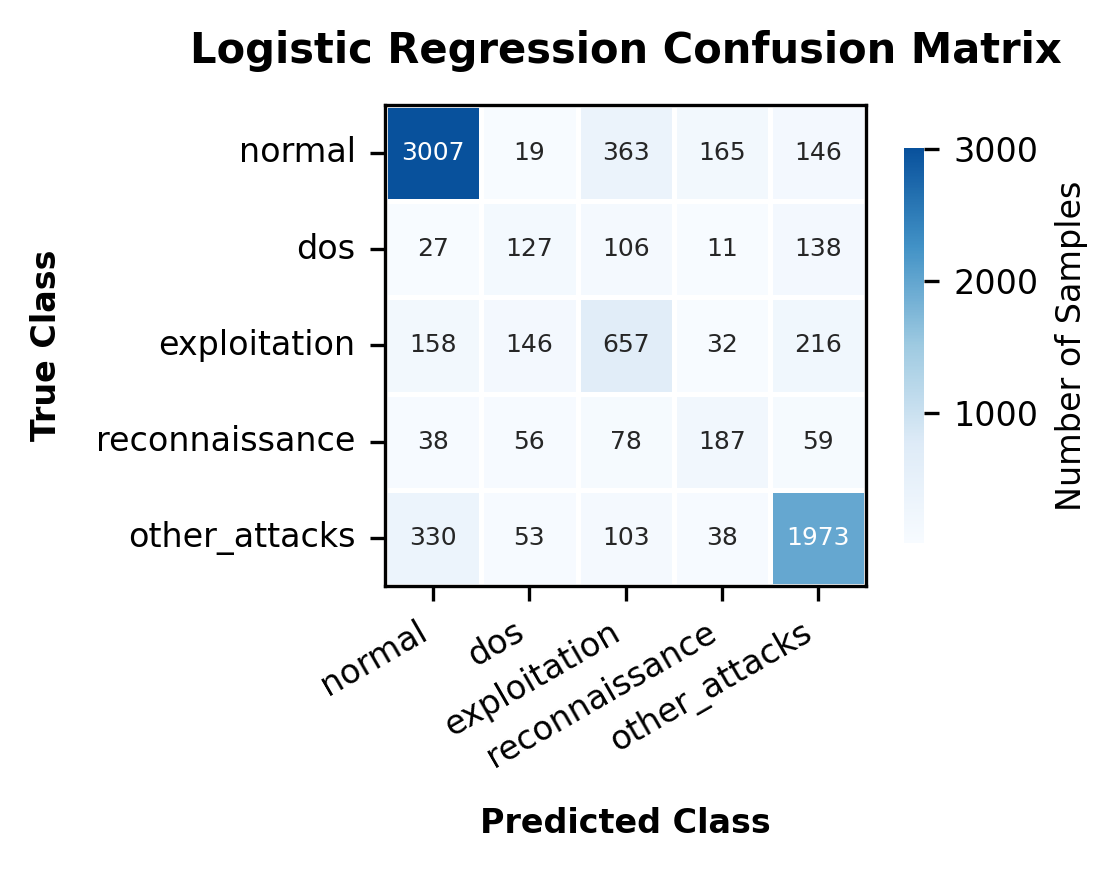


KNN
                precision    recall  f1-score   support

        normal     0.8915    0.9662    0.9274      3700
           dos     0.3661    0.4010    0.3827       409
  exploitation     0.6409    0.6658    0.6531      1209
reconnaissance     0.6735    0.4737    0.5562       418
 other_attacks     0.9303    0.8290    0.8767      2497

      accuracy                         0.8274      8233
     macro avg     0.7005    0.6671    0.6792      8233
  weighted avg     0.8293    0.8274    0.8258      8233

Accuracy        : 0.8274
Macro Precision : 0.7005
Macro Recall    : 0.6671
Macro F1        : 0.6792

Confusion Matrix:
[[3575    3   28   26   68]
 [  27  164  190    9   19]
 [ 111  194  805   47   52]
 [  64   48   92  198   16]
 [ 233   39  141   14 2070]]


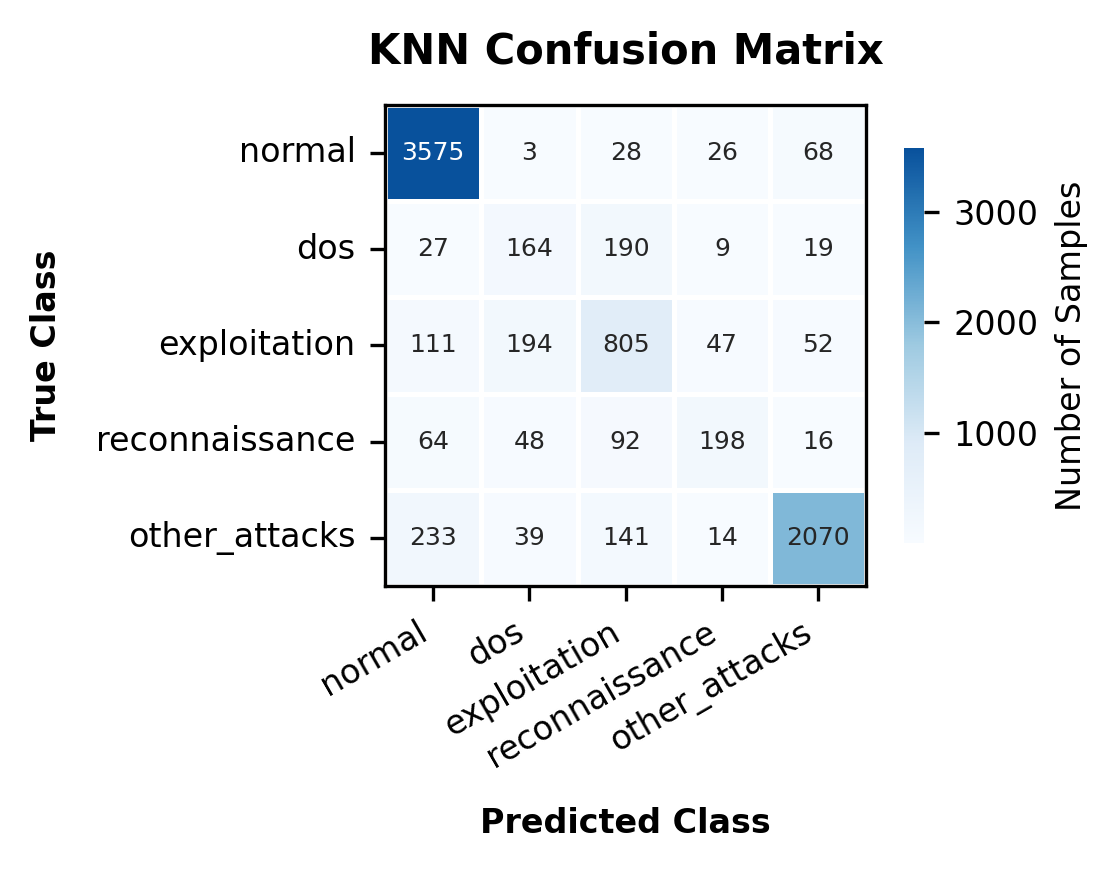


Random Forest
                precision    recall  f1-score   support

        normal     0.9091    0.9727    0.9398      3700
           dos     0.3721    0.3521    0.3618       409
  exploitation     0.6198    0.7213    0.6667      1209
reconnaissance     0.7652    0.4833    0.5924       418
 other_attacks     0.9486    0.8418    0.8920      2497

      accuracy                         0.8404      8233
     macro avg     0.7229    0.6742    0.6905      8233
  weighted avg     0.8446    0.8404    0.8388      8233

Accuracy        : 0.8404
Macro Precision : 0.7229
Macro Recall    : 0.6742
Macro F1        : 0.6905

Confusion Matrix:
[[3599    0   33   20   48]
 [  17  144  234    8    6]
 [  82  186  872   23   46]
 [  60   37  105  202   14]
 [ 201   20  163   11 2102]]


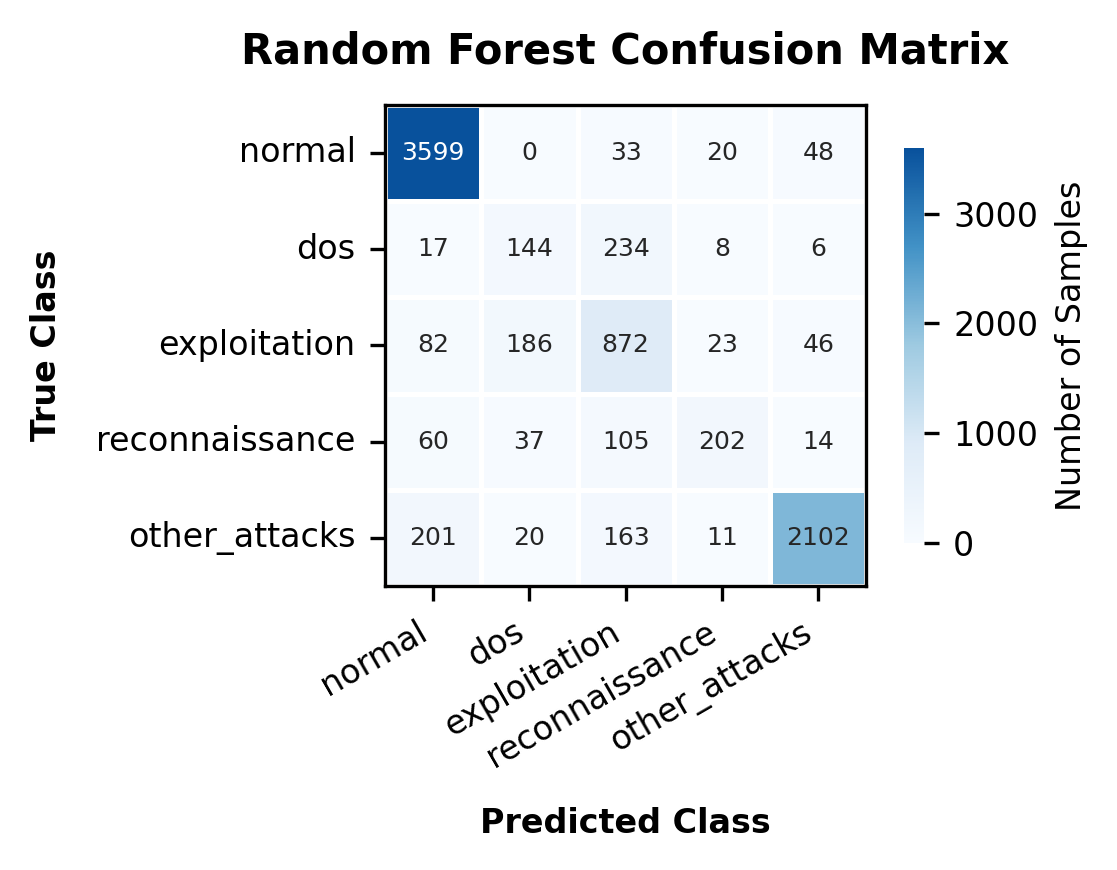


Extra Trees
                precision    recall  f1-score   support

        normal     0.9054    0.9751    0.9390      3700
           dos     0.3884    0.4254    0.4061       409
  exploitation     0.6344    0.7105    0.6703      1209
reconnaissance     0.7757    0.4880    0.5991       418
 other_attacks     0.9620    0.8410    0.8974      2497

      accuracy                         0.8436      8233
     macro avg     0.7332    0.6880    0.7024      8233
  weighted avg     0.8505    0.8436    0.8432      8233

Accuracy        : 0.8436
Macro Precision : 0.7332
Macro Recall    : 0.6880
Macro F1        : 0.7024

Confusion Matrix:
[[3608    1   30   18   43]
 [  17  174  204    7    7]
 [  92  206  859   26   26]
 [  67   41   99  204    7]
 [ 201   26  162    8 2100]]


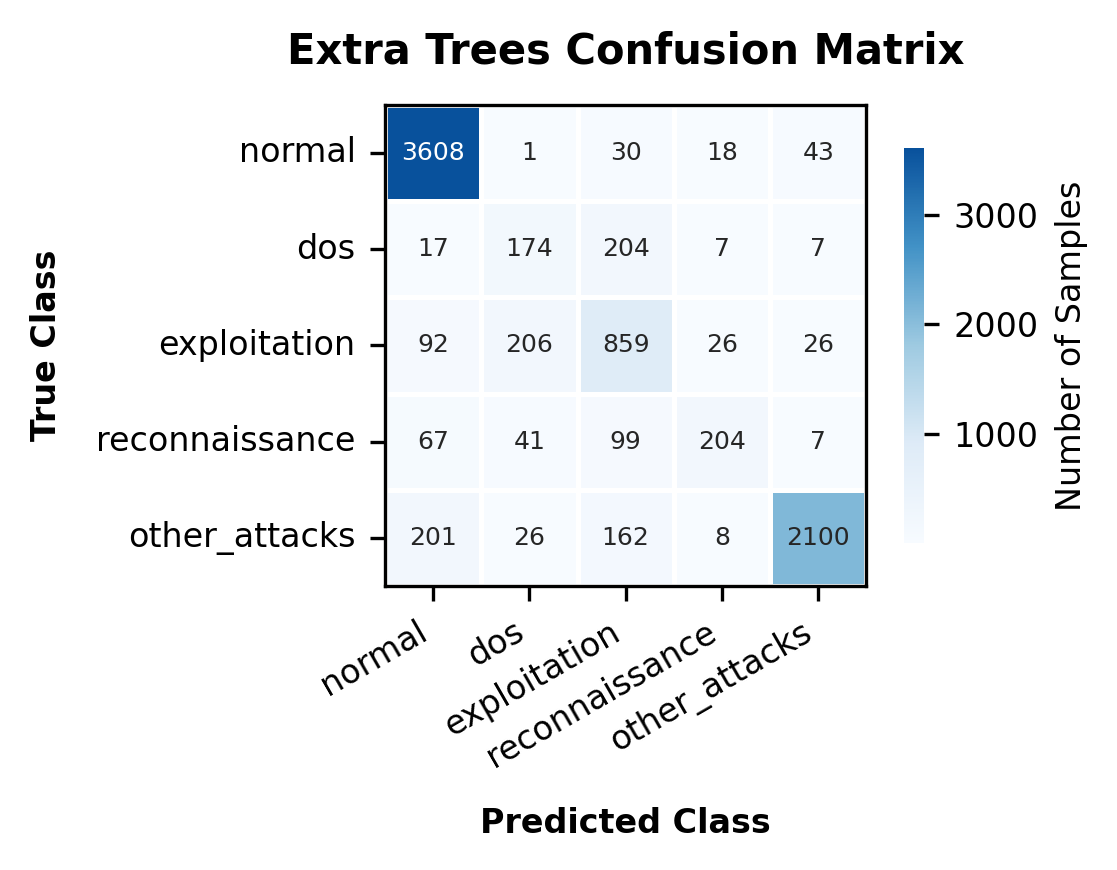


XGBoost
                precision    recall  f1-score   support

        normal     0.9137    0.9705    0.9413      3700
           dos     0.4174    0.4694    0.4419       409
  exploitation     0.6445    0.7138    0.6774      1209
reconnaissance     0.7319    0.4833    0.5821       418
 other_attacks     0.9497    0.8474    0.8957      2497

      accuracy                         0.8459      8233
     macro avg     0.7315    0.6969    0.7077      8233
  weighted avg     0.8512    0.8459    0.8457      8233

Accuracy        : 0.8459
Macro Precision : 0.7315
Macro Recall    : 0.6969
Macro F1        : 0.7077

Confusion Matrix:
[[3591    1   40   25   43]
 [  19  192  181    8    9]
 [  77  194  863   30   45]
 [  59   46   96  202   15]
 [ 184   27  159   11 2116]]


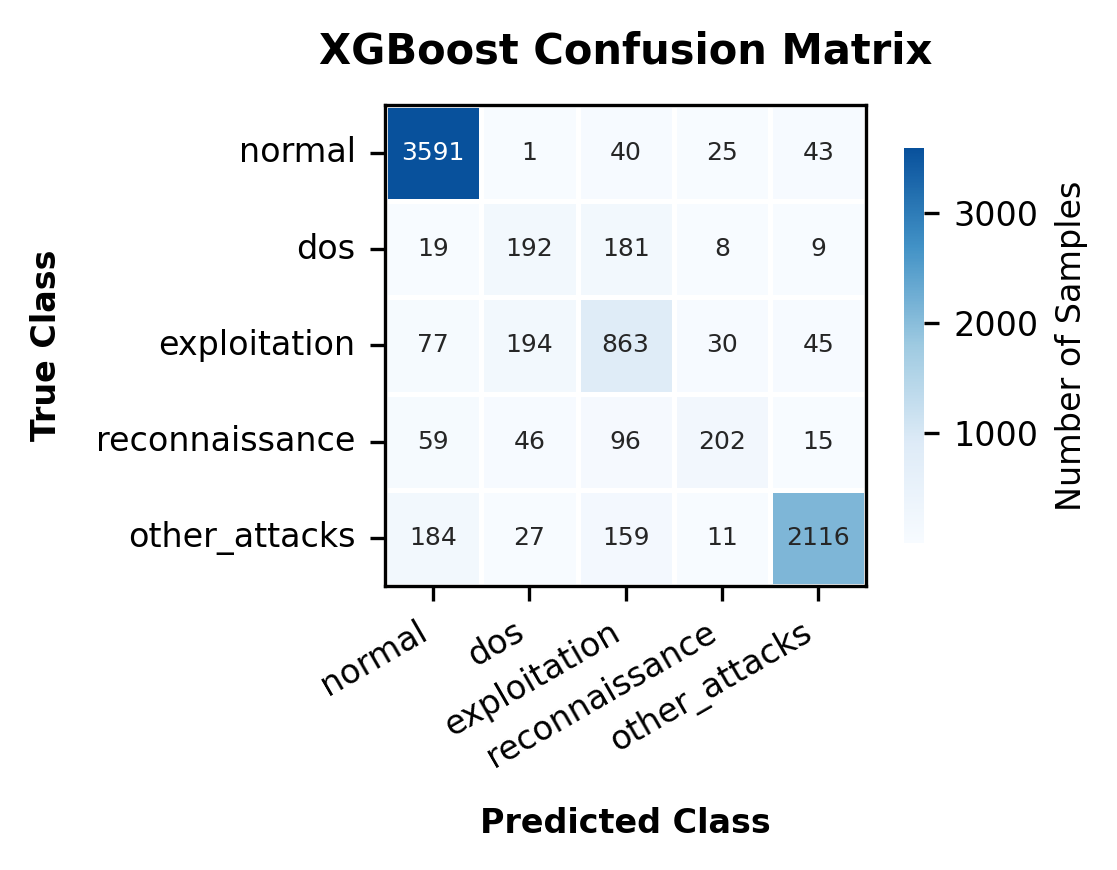


LightGBM
                precision    recall  f1-score   support

        normal     0.9078    0.9692    0.9375      3700
           dos     0.4209    0.4621    0.4406       409
  exploitation     0.6540    0.7097    0.6807      1209
reconnaissance     0.7384    0.4928    0.5911       418
 other_attacks     0.9420    0.8462    0.8916      2497

      accuracy                         0.8444      8233
     macro avg     0.7326    0.6960    0.7083      8233
  weighted avg     0.8481    0.8444    0.8436      8233

Accuracy        : 0.8444
Macro Precision : 0.7326
Macro Recall    : 0.6960
Macro F1        : 0.7083

Confusion Matrix:
[[3586    4   42   22   46]
 [  19  189  177    9   15]
 [  81  187  858   30   53]
 [  61   40   95  206   16]
 [ 203   29  140   12 2113]]


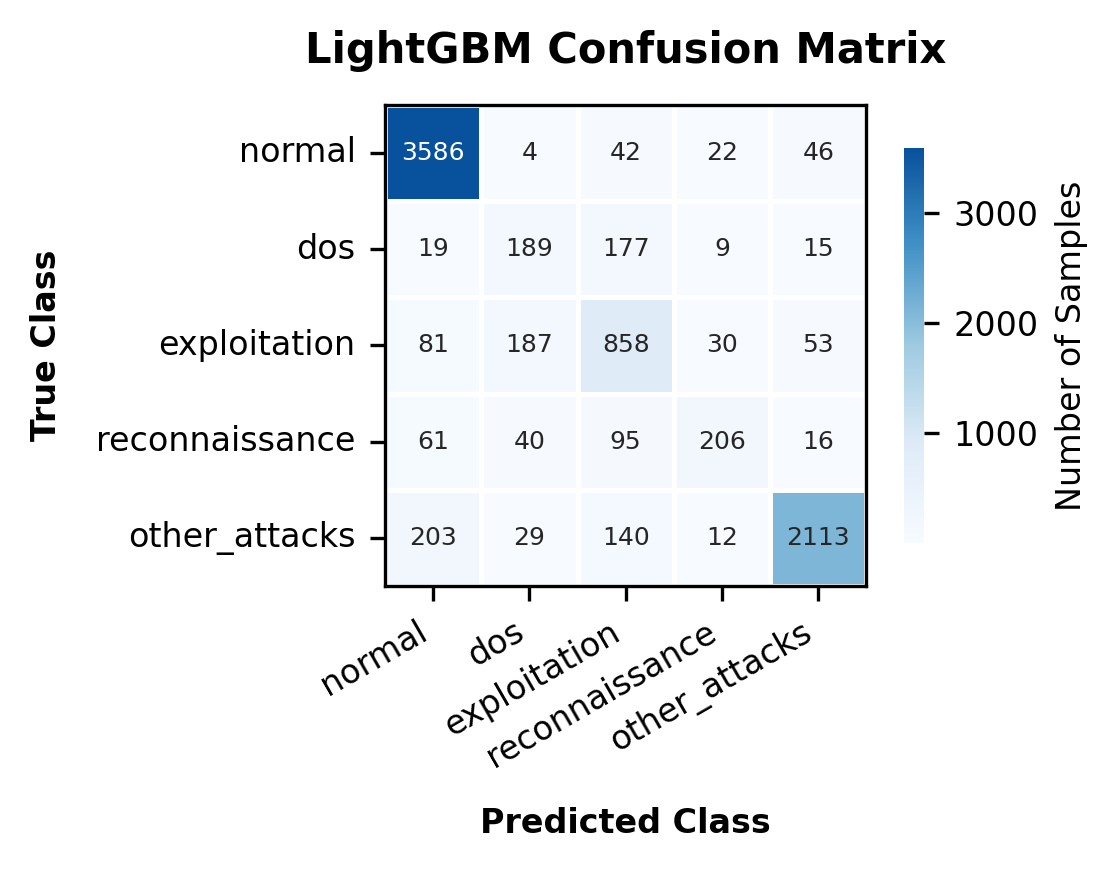


HGBoosting
                precision    recall  f1-score   support

        normal     0.9131    0.9689    0.9402      3700
           dos     0.4081    0.4450    0.4257       409
  exploitation     0.6370    0.7113    0.6721      1209
reconnaissance     0.7338    0.4880    0.5862       418
 other_attacks     0.9449    0.8450    0.8922      2497

      accuracy                         0.8431      8233
     macro avg     0.7274    0.6917    0.7033      8233
  weighted avg     0.8480    0.8431    0.8427      8233

Accuracy        : 0.8431
Macro Precision : 0.7274
Macro Recall    : 0.6917
Macro F1        : 0.7033

Confusion Matrix:
[[3585    3   39   26   47]
 [  16  182  190    6   15]
 [  80  191  860   30   48]
 [  56   43  102  204   13]
 [ 189   27  159   12 2110]]


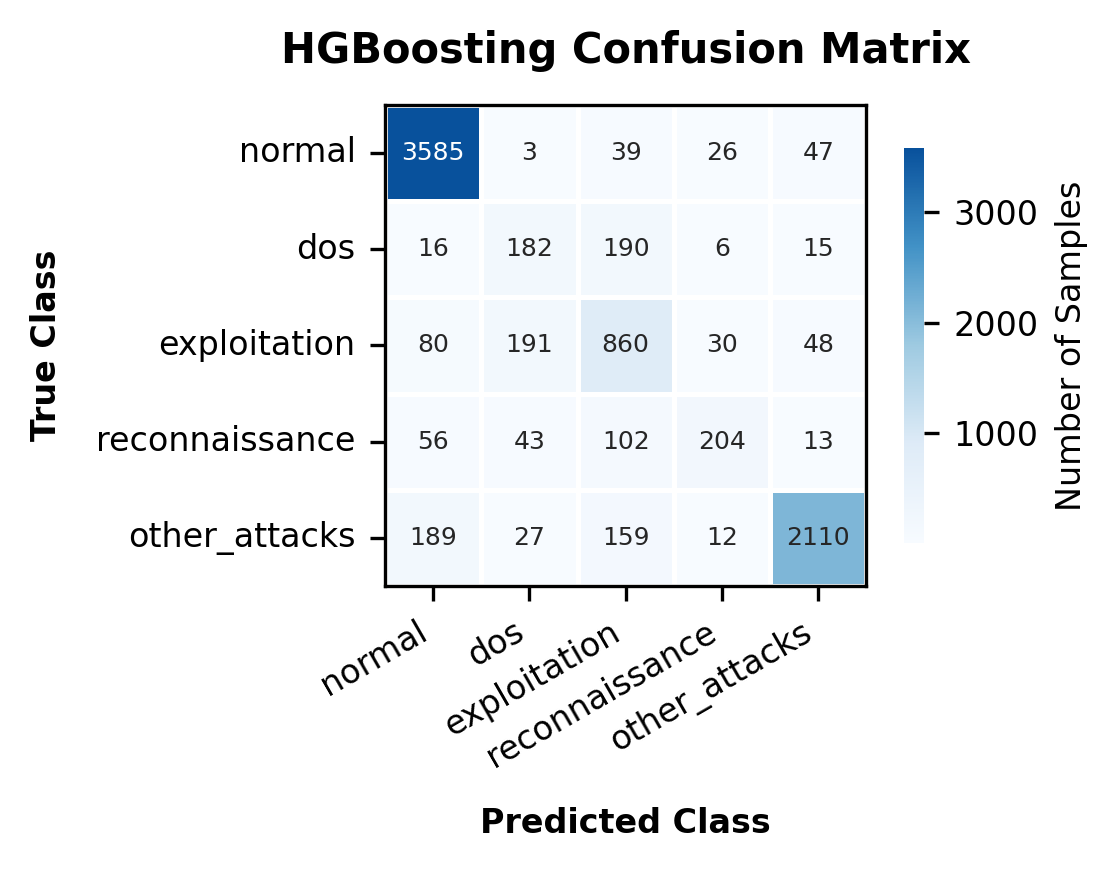


FINAL CLASSIFIER COMPARISON
              Model  Accuracy  Macro Precision  Macro Recall  Macro F1
           LightGBM  0.844407         0.732628      0.696002  0.708285
            XGBoost  0.845864         0.731451      0.696892  0.707672
         HGBoosting  0.843071         0.727396      0.691658  0.703292
        Extra Trees  0.843556         0.733170      0.688023  0.702381
      Random Forest  0.840398         0.722925      0.674220  0.690532
                KNN  0.827402         0.700465      0.667143  0.679234
Logistic Regression  0.722823         0.575029      0.580831  0.577669


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
import xgboost as xgb
import lightgbm as lgb

CLASS_NAMES = ["normal","dos","exploitation","reconnaissance","other_attacks"]
RESULT_DIR = "balanced_classifier_results"
os.makedirs(RESULT_DIR, exist_ok=True)

models = {
    "Logistic Regression": LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9, objective="multi:softprob", num_class=5, eval_metric="mlogloss", tree_method="hist", random_state=SEED, n_jobs=-1),
    "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, objective="multiclass", num_class=5, random_state=SEED, n_jobs=-1, verbosity=-1),
    "HGBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED)}

results = []
ae.eval()
with torch.no_grad():
    Z_test = ae.encoder(torch.from_numpy(X_test).to(DEVICE)).cpu().numpy().astype(np.float32)
Z_test_n = latent_scaler.transform(Z_test).astype(np.float32)
for model_name, model in models.items():
    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    model.fit(Z_train_balanced, y_train_balanced)
    y_pred = model.predict(Z_test_n)
    report = classification_report(y_test,y_pred,target_names=CLASS_NAMES,digits=4,zero_division=0)
    print(report)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    print(f"Accuracy        : {accuracy:.4f}")
    print(f"Macro Precision : {precision:.4f}")
    print(f"Macro Recall    : {recall:.4f}")
    print(f"Macro F1        : {f1:.4f}")

    safe_name = model_name.replace(" ", "_")
    with open(os.path.join(RESULT_DIR, f"{safe_name}_classification_report.txt"), "w") as f:
        f.write(f"{model_name} - Classification Report\n")
        f.write("=" * 80 + "\n")
        f.write(report)
        f.write("\n")
        f.write(f"Accuracy        : {accuracy:.4f}\n")
        f.write(f"Macro Precision : {precision:.4f}\n")
        f.write(f"Macro Recall    : {recall:.4f}\n")
        f.write(f"Macro F1        : {f1:.4f}\n")

    plt.figure(figsize=(4, 3), dpi=300)
    from matplotlib.colors import LinearSegmentedColormap
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)))
    cmap = LinearSegmentedColormap.from_list("PLOS_Blue",["#F7FBFF", "#DEEBF7", "#9ECAE1", "#4292C6", "#08519C"])
    ax = sns.heatmap(cm,annot=True,fmt="d",cmap=cmap,square=True,linewidths=0.8,linecolor="white",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,cbar=True,
    annot_kws={"fontsize": 6},
    cbar_kws={"shrink": 0.82, "label": "Number of Samples"})
    ax.set_xlabel("Predicted Class", fontsize=8, fontweight="bold", labelpad=8)
    ax.set_ylabel("True Class", fontsize=8, fontweight="bold", labelpad=8)
    ax.set_title(f"{model_name} Confusion Matrix",fontsize=10,fontweight="bold",pad=10)

    plt.xticks(rotation=30, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=8)
    cbar.set_label("Number of Samples", fontsize=8)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, f"{safe_name}_confusion_matrix.png"),dpi=600,bbox_inches="tight",facecolor="white")
    plt.show()
    plt.close()

    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(os.path.join(RESULT_DIR, f"{safe_name}_confusion_matrix.csv"))
    results.append({ "Model": model_name, "Accuracy": accuracy,"Macro Precision": precision,"Macro Recall": recall,"Macro F1": f1})

# ============================================================
# FINAL COMPARISON TABLE
# ============================================================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Macro F1",ascending=False).reset_index(drop=True)
print("\n" + "=" * 80)
print("FINAL CLASSIFIER COMPARISON")
print("=" * 80)
print(results_df.to_string(index=False))
results_df.to_csv(os.path.join(RESULT_DIR, "all_classifier_results.csv"),index=False)